In [1]:
import os, glob
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'CCCA')
pth_dev = os.path.join(pth_data, 'development', 'modeling')
pth_mod = os.path.join(pth_data, 'features', 'biomart', 'modules')
pth_out = os.path.join(pth, 'figures', 'cancer', 'CCCA')

In [3]:
adata_dev = sc.read_h5ad(os.path.join(pth_dev, 'spectrum.h5ad'))
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
adata

AnnData object with n_obs × n_vars = 1406087 × 513
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores

In [4]:
mod_fn = sorted(glob.glob(os.path.join(pth_mod, '*.csv')))
get_name = lambda fn: os.path.split(fn)[1].replace('.csv', '')
mod_dict = {get_name(fn) : pd.read_csv(fn) for fn in mod_fn}

# module signatures
for mod, df_mod in mod_dict.items():
    if mod != 'ref':
        print(mod)
        g = df_mod.hsapiens.copy()
        for _, df_group in adata.obs.groupby('source', observed = True):
            msk = adata.obs_names.isin(df_group.index)
            adata_group = adata[msk].copy()
            sc.tl.score_genes(adata_group,
                              gene_list = g,
                              score_name = mod,
                              ctrl_as_ref = False,
                              random_state = 1234)
            adata.obs.loc[msk, mod] = adata_group.obs[mod]

adata.obsm['X_spectrum'] = adata.obs[['late', 'early']].values

early
late


In [5]:
# select spectrum (Mes1 | Mes2 > .1)
X_mes = adata.obs[['Mes1', 'Mes2']]
msk = (X_mes > .1).any(axis = 1)
adata.obs['spectrum'] = msk.astype(str)

In [6]:
adata = adata[adata.obs.spectrum == 'True'].copy()
adata.write(os.path.join(pth_in, 'spectrum.h5ad'))
adata

AnnData object with n_obs × n_vars = 149645 × 513
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores'

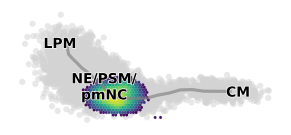

In [9]:
# plot density (hexbin)
nx, figsize = 100, (3.5, 1.5)
fig, ax = plt.subplots(1, 1, figsize = figsize)
sc.pl.embedding(adata_dev, 'X_spectrum', size = 80, alpha = .5,
                frameon = False, show = False, ax = ax)
xlim = ax.get_xlim(); ylim = ax.get_ylim()
x, y = adata.obs[['late', 'early']].values.T
ar_data = (xlim[1] - xlim[0]) / (ylim[1] - ylim[0])
ar_fig = (figsize[0] / figsize[1])
ny = int((nx / np.sqrt(3)) * (ar_data / ar_fig))
hb = ax.hexbin(x, y, gridsize = [nx, ny], bins = 'log',
               extent = [*xlim, *ylim], cmap = 'viridis',
               linewidths = 0, mincnt = 60)

# show curve, celltypes
df_dev = adata_dev.obs[['late', 'early', 't']].copy()
df_dev['t_bin'] = pd.cut(df_dev.t, 20)
df_dev = df_dev.groupby('t_bin', observed = True).mean()
ax.plot(df_dev.late, df_dev.early, lw = 2.25, color = 'gray', alpha = .65)
sc.pl.embedding(adata_dev, 'X_spectrum', size = 80, alpha = 0,
                color = 'celltype', legend_loc = 'on data',
                legend_fontoutline = 1, frameon = False,
                show = False, ax = ax)
ax.set_xlim(xlim); ax.set_ylim(ylim); ax.set_title('')

label_dict = {
    'Cranial Mesenchyme'         : 'CM',
    'Lateral Plate Mesoderm'     : 'LPM',
    'Premigratory Neural Crest'  : 'NE/PSM/\npmNC',
    'Migratory Neural Crest'     : '',
    'nan'                        : '',
    'Nascent Endothelium'        : '',
    'Neuroglial Progenitors'     : '',
    'Neuromesodermal Progenitor' : '',
    'Presomitic Mesoderm'        : '',
    'Somite'                     : ''}

pos_dict = {
    'Cranial Mesenchyme'         : (.06, -.01),
    'Lateral Plate Mesoderm'     : (-.066, .25),
    'Premigratory Neural Crest'  : (0, -.03)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, 'spectrum.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_2055009/843229831.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(hb, cax = cax)


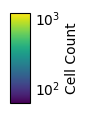

In [8]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(hb, cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Cell Count')
fn = os.path.join(pth_out, 'colorbar.pdf')
plt.savefig(fn, bbox_inches = 'tight')